# 01 · The eager HF model

The reference is the checkpoint's own PyTorch code (`modeling.py`, loaded with `trust_remote_code`).
This notebook:
- lists what is inside it;
- records the shape and dtype at each module boundary;
- draws the block-causal mask;
- walks through one Fast-dLLM v2 refinement step by hand;
- traces a whole generation call by call, and checks that the trace reproduces `model.generate()` exactly.

**Needs:** CUDA, and the cached checkpoint (about 3.1 GB in bf16). Takes about a minute.

In [1]:
from _helpers import *
bootstrap()

repo root: fast-dllm-relax/  (cwd set)  tvm 0.24.dev0  torch 2.10.0+cu128


PosixPath('<repo>')

In [2]:
import torch
tok, hf = load_hf()
cfg = hf.config
fields = ["num_hidden_layers", "hidden_size", "intermediate_size", "num_attention_heads", "num_key_value_heads",
          "head_dim", "vocab_size", "max_position_embeddings", "rope_theta", "rms_norm_eps",
          "tie_word_embeddings", "bd_size", "torch_dtype"]
print_table([{"config": f, "value": getattr(cfg, f, None)} for f in fields])

config                   value         
-----------------------  --------------
num_hidden_layers        28            
hidden_size              1536          
intermediate_size        8960          
num_attention_heads      12            
num_key_value_heads      2             
head_dim                               
vocab_size               151936        
max_position_embeddings  32768         
rope_theta               1e+06         
rms_norm_eps             1e-06         
tie_word_embeddings      True          
bd_size                  32            
torch_dtype              torch.bfloat16


## What is inside

This is a Qwen2-style decoder:
- 28 identical layers;
- grouped-query attention, with 12 query heads sharing 2 K/V heads;
- RMSNorm and a SwiGLU MLP;
- biases on q/k/v only.

There is one embedding matrix, and `lm_head` is *tied* to it, meaning it shares the same storage.

In [3]:
print(hf.model.layers[0])
print(f"... x {len(hf.model.layers)} layers")
print("final norm:", hf.model.norm)
print("lm_head:   ", hf.lm_head)

Fast_dLLM_QwenDecoderLayer(
  (self_attn): Fast_dLLM_QwenAttention(
    (q_proj): Linear(in_features=1536, out_features=1536, bias=True)
    (k_proj): Linear(in_features=1536, out_features=256, bias=True)
    (v_proj): Linear(in_features=1536, out_features=256, bias=True)
    (o_proj): Linear(in_features=1536, out_features=1536, bias=False)
  )
  (mlp): Fast_dLLM_QwenMLP(
    (gate_proj): Linear(in_features=1536, out_features=8960, bias=False)
    (up_proj): Linear(in_features=1536, out_features=8960, bias=False)
    (down_proj): Linear(in_features=8960, out_features=1536, bias=False)
    (act_fn): SiLU()
  )
  (input_layernorm): Fast_dLLM_QwenRMSNorm((1536,), eps=1e-06)
  (post_attention_layernorm): Fast_dLLM_QwenRMSNorm((1536,), eps=1e-06)
)
... x 28 layers
final norm: Fast_dLLM_QwenRMSNorm((1536,), eps=1e-06)
lm_head:    Linear(in_features=1536, out_features=151936, bias=False)


In [4]:
sd = hf.state_dict()
params = list(hf.parameters())          # de-duplicates shared tensors
n = sum(p.numel() for p in params)
print(f"state_dict entries: {len(sd)}   unique parameter tensors: {len(params)}")
print(f"lm_head.weight is embed_tokens.weight (same storage): "
      f"{hf.lm_head.weight.data_ptr() == hf.model.embed_tokens.weight.data_ptr()}")
print(f"parameters: {n / 1e9:.3f} B  = {n * 2 / 1e9:.2f} GB in bf16")

state_dict entries: 339   unique parameter tensors: 338
lm_head.weight is embed_tokens.weight (same storage): True
parameters: 1.544 B  = 3.09 GB in bf16


## Shapes and dtypes at each module boundary

Forward hooks record one plain forward pass (no cache) over the chat-templated prompt.

In [5]:
PROMPT = 'Natalia sold clips to 48 of her friends in April, and then she sold half as many clips in May. How many clips did Natalia sell altogether in April and May?'
ids = chat_ids(tok, PROMPT)
L = len(ids)
x = torch.tensor([ids], device=hf.device)
print(f"prompt tokens: {L}  ({L // 32} full blocks + {L % 32})")

records = []
def hook(name):
    def f(mod, args, kwargs, out):
        inp = args[0] if args else next(iter(kwargs.values()))
        o = out[0] if isinstance(out, tuple) else out
        records.append({"module": name, "in": tuple(inp.shape), "in dtype": str(inp.dtype)[6:],
                        "out": tuple(o.shape), "out dtype": str(o.dtype)[6:]})
    return f

l0 = hf.model.layers[0]
targets = {
    "embed_tokens": hf.model.embed_tokens, "layers.0.input_layernorm": l0.input_layernorm,
    "layers.0.self_attn.q_proj": l0.self_attn.q_proj, "layers.0.self_attn.k_proj": l0.self_attn.k_proj,
    "layers.0.self_attn": l0.self_attn, "layers.0.mlp.gate_proj": l0.mlp.gate_proj, "layers.0.mlp": l0.mlp,
    "layers.0": l0, "norm": hf.model.norm, "lm_head": hf.lm_head,
}
handles = [m.register_forward_hook(hook(k), with_kwargs=True) for k, m in targets.items()]
with torch.no_grad():
    out = hf(input_ids=x)
for h in handles:
    h.remove()
print_table(records)

prompt tokens: 58  (1 full blocks + 26)
module                     in             in dtype  out              out dtype
-------------------------  -------------  --------  ---------------  ---------
embed_tokens               (1, 58)        int64     (1, 58, 1536)    bfloat16 
layers.0.input_layernorm   (1, 58, 1536)  bfloat16  (1, 58, 1536)    bfloat16 
layers.0.self_attn.q_proj  (1, 58, 1536)  bfloat16  (1, 58, 1536)    bfloat16 
layers.0.self_attn.k_proj  (1, 58, 1536)  bfloat16  (1, 58, 256)     bfloat16 
layers.0.self_attn         (1, 58, 1536)  bfloat16  (1, 58, 1536)    bfloat16 
layers.0.mlp.gate_proj     (1, 58, 1536)  bfloat16  (1, 58, 8960)    bfloat16 
layers.0.mlp               (1, 58, 1536)  bfloat16  (1, 58, 1536)    bfloat16 
layers.0                   (1, 58, 1536)  bfloat16  (1, 58, 1536)    bfloat16 
norm                       (1, 58, 1536)  bfloat16  (1, 58, 1536)    bfloat16 
lm_head                    (1, 58, 1536)  bfloat16  (1, 58, 151936)  bfloat16 


Everything stays in bf16, logits included. Inside, RMSNorm normalizes in fp32 before casting back, and
SDPA accumulates in fp32. Notebook 03 shows where the Relax version deliberately copies (or changes)
that precision order.

## The block-causal mask

Outside the KV cache, a query at position *q* may attend to key *k* when `q // 32 >= k // 32`
(`eval_block_diff_mask`). Blocks are therefore causal with respect to each other but fully
bidirectional inside. When a 32-token block is scored against a cache of completed blocks, every
entry is allowed, so the cached steps need no mask at all. The Relax model relies on this.

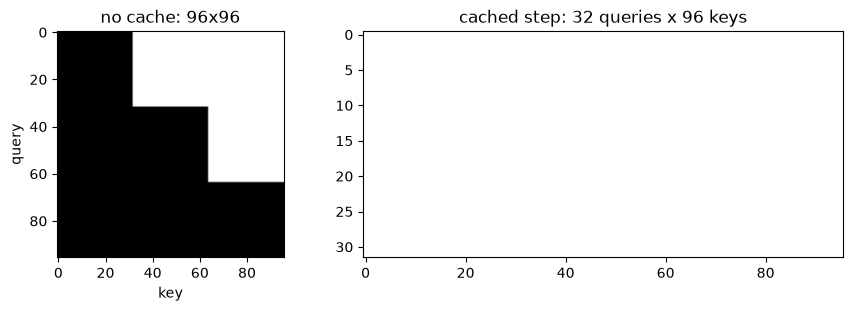

cached-step mask all True: True


In [6]:
import matplotlib.pyplot as plt
m_full = hf.model.eval_mask(96, 32, 0).numpy()          # 96 tokens, no cache
m_cached = hf.model.eval_mask(32, 32, 64).numpy()       # one block against a 64-token cache
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2), gridspec_kw={"width_ratios": [1, 1.6]})
ax[0].imshow(m_full, cmap="Greys"); ax[0].set_title("no cache: 96x96"); ax[0].set_xlabel("key"); ax[0].set_ylabel("query")
ax[1].imshow(m_cached, cmap="Greys", aspect="auto"); ax[1].set_title("cached step: 32 queries x 96 keys")
plt.tight_layout(); plt.show()
print("cached-step mask all True:", bool(m_cached.all()))

## One refinement step by hand

`generate()` does the following:
1. **Prefill.** If the prompt is longer than one block, run its complete blocks once with
   `update_past_key_values=True`. That builds the KV cache.
2. **Pad.** Fill out the last, partial block with mask tokens. The *active block* is the last 32
   positions: the prompt tail, then the masks.
3. **Refine.** For each 8-token sub-block, repeatedly run the active block against the cache (cache not
   updated), shift the logits, softmax, and unmask the confident positions.
4. **Append.** Once the block is complete, run it with `update_past_key_values=True` to extend the cache,
   and append the argmax of its last position as the first token of the next block.

Steps 1–3 by hand, for the first refinement step:

In [7]:
BS, SBS, THR, MASK = 32, 8, 0.9, 151665
assert L > BS and L % BS != 0, "pick a prompt longer than one block and not block-aligned (see research 001 Q1)"
n_prefix = L // BS * BS
with torch.no_grad():
    pre = hf(input_ids=x[:, :n_prefix], use_cache=True, update_past_key_values=True, block_size=BS)
past = pre.past_key_values
print(f"prefill: {n_prefix} tokens -> cache length {past.get_seq_length()}, "
      f"layer-0 K shape {tuple(past[0][0].shape)}  ([batch, kv_heads, cached_len, head_dim])")

x_t = torch.cat([x, torch.full((1, BS - L % BS), MASK, device=x.device)], dim=1)
block = x_t[:, -BS:]
print("active block:", tok.convert_ids_to_tokens(block[0].tolist()))

prefill: 32 tokens -> cache length 32, layer-0 K shape (1, 2, 32, 128)  ([batch, kv_heads, cached_len, head_dim])
active block: ['Ġsold', 'Ġhalf', 'Ġas', 'Ġmany', 'Ġclips', 'Ġin', 'ĠMay', '.', 'ĠHow', 'Ġmany', 'Ġclips', 'Ġdid', 'ĠNatal', 'ia', 'Ġsell', 'Ġaltogether', 'Ġin', 'ĠApril', 'Ġand', 'ĠMay', '?', '<|im_end|>', 'Ċ', '<|im_start|>', 'assistant', 'Ċ', '|<MASK>|', '|<MASK>|', '|<MASK>|', '|<MASK>|', '|<MASK>|', '|<MASK>|']


In [8]:
with torch.no_grad():
    out = hf(input_ids=block, use_cache=True, past_key_values=past, update_past_key_values=False)
logits = torch.cat([out.logits[:, :1], out.logits[:, :-1]], dim=1)     # the shift
sb = (L % BS) // SBS                       # first sub-block that contains masks
s0 = sb * SBS
p = torch.softmax(logits[0, s0:s0 + SBS], dim=-1)                      # bf16, as generate() does
conf, pred = p.max(dim=-1)
is_mask = block[0, s0:s0 + SBS] == MASK
masked_conf = torch.where(is_mask, conf.float(), torch.tensor(-1.0, device=conf.device))
unmask = (masked_conf > THR) | (torch.arange(SBS, device=conf.device) == masked_conf.argmax())
unmask &= is_mask
print_table([{"block pos": s0 + i, "current": tok.convert_ids_to_tokens(int(block[0, s0 + i])),
              "masked": bool(is_mask[i]), "prediction": tok.convert_ids_to_tokens(int(pred[i])),
              "confidence": round(float(conf[i]), 4), "unmask now": bool(unmask[i])} for i in range(SBS)])

block pos  current    masked  prediction  confidence  unmask now
---------  ---------  ------  ----------  ----------  ----------
24         assistant  False   Ċ           0.9961      False     
25         Ċ          False   ĠTo         0.6953      False     
26         |<MASK>|   True    To          0.9961      True      
27         |<MASK>|   True    Ġdetermine  0.9922      True      
28         |<MASK>|   True    Ġthe        0.9648      True      
29         |<MASK>|   True    Ġtotal      0.9727      True      
30         |<MASK>|   True    Ġnumber     0.9531      True      
31         |<MASK>|   True    Ġof         0.9531      True      


Only masked positions can be unmasked. Every position whose confidence is above 0.9 is taken in one
step, which is how Fast-dLLM decodes several tokens per forward pass. If none clears 0.9, the single
best one is taken.

## A whole generation, call by call

`hf_traced_generate` (in `_helpers.py`) re-implements `generate()` line for line
(`use_block_cache=False`, greedy) and records every forward call. The cell then checks that it
reproduces `model.generate()` token for token.

In [9]:
ids_traced, events = hf_traced_generate(hf, x, max_new_tokens=64)
with torch.no_grad():
    ref = hf.generate(x, tokenizer=tok, max_new_tokens=64, block_size=32, small_block_size=8, threshold=0.9,
                      use_block_cache=False, temperature=0.0, top_p=0.95, mask_id=MASK, stop_token=151645)
print("trace reproduces model.generate():", ref[0].tolist() == ids_traced)
events_table(events, tok)

trace reproduces model.generate(): True
step  kind     tokens_in  cache_len  sub_block  rows                      conf                                                        text                                
----  -------  ---------  ---------  ---------  ------------------------  ----------------------------------------------------------  ------------------------------------
0     prefill  32         32                                                                                                                                              
1     full     32         32         3          [2, 3, 4, 5, 6, 7]        [0.9961, 0.9922, 0.9648, 0.9727, 0.9531, 0.9531]            'To determine the total number of'  
2     append   32         64                                                                                                          ' clips'                            
3     full     32         64         0          [1, 2, 3, 4]              [0.9961, 0.9961, 1.0, 0.9805]  

In [10]:
import collections
kinds = collections.Counter(e["kind"] for e in events)
full = [e for e in events if e["kind"] == "full"]
new_tokens = sum(len(e["unmasked_rows"]) for e in full)
print(f"forward calls: {dict(kinds)}")
print(f"tokens unmasked by refinement steps: {new_tokens} in {len(full)} steps "
      f"= {new_tokens / max(len(full), 1):.2f} tokens per full forward")
print("\ncontinuation:", repr(tok.decode(ids_traced[L:], skip_special_tokens=True)))

forward calls: {'prefill': 1, 'full': 9, 'append': 2}
tokens unmasked by refinement steps: 37 in 9 steps = 4.11 tokens per full forward

continuation: 'To determine the total number of clips Natalia sold in April and May, we need to follow these steps:\n\n1. Identify the number of clips Natalia sold in April.\n2. Calculate the'


## Takeaways
- HF uses **one** `forward()` for every step. Flags (`use_cache`, `update_past_key_values`,
  `use_block_cache`, `replace_position`) and a mutable `DynamicCache` choose what it does. TVM needs
  each of those modes as its own function with declared shapes (notebook 02).
- Cached steps attend over the whole cache plus the block, so they need **no mask**. Only the
  no-cache prefill uses the block-causal mask.
- The tied `lm_head` is a second *name* for the embedding matrix. Exporting both names naively would
  store 466 MB twice (resolved in this repo; see notebook 02).
- Next: **02 · From HF to `relax.frontend.nn`**.